# Kazakhtelecom: is the village last mile the bottleneck of home internet?

**Problem:**
- Kazakhstan's median fixed broadband is 88.1 Mbps, against a world median of 118.8 Mbps.
- Users filed 67,544 complaints about home internet in 2025.
- Kazakhtelecom holds about 66% of fixed broadband.

**Bottleneck (my claim):** the copper last mile in villages, not the network as a whole.

**Data (real):**
- Ookla Speedtest Open Data, fixed tiles (~610 m) Q3 2025 and Q3 2026, mobile tiles Q3 2026, CC BY-NC-SA 4.0.
- Kazakhstan regions from geoBoundaries (CC BY 4.0).
- Settlements and their population from GeoNames KZ (CC BY 4.0).

The hypotheses and the city/town/village rule were written before the data was opened (`hypotheses.md`).

In [1]:
import json, zipfile, numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from shapely.geometry import shape
from shapely import contains_xy
pd.set_option('display.width', 160)
raw = pd.read_csv('data_raw.csv', dtype={'quadkey': str})
print(raw.shape); raw.describe().T

(194851, 10)


,count,mean,std,min,25%,50%,75%,max
tile_x,194851.0,66.306405,11.580883,46.4035,55.7034,69.3979,75.0284,8.739900e+01
tile_y,194851.0,46.902171,5.270431,40.5034,42.2712,44.4750,52.3219,5.549910e+01
avg_d_kbps,194851.0,118306.016058,124454.141757,1.0000,31055.5000,80412.0000,169798.0000,1.881836e+06
avg_u_kbps,194851.0,88718.696466,102811.475374,1.0000,15239.0000,49038.0000,129867.0000,1.060782e+06
avg_lat_ms,194851.0,25.821848,47.957636,0.0000,6.0000,14.0000,27.0000,2.744000e+03
tests,194851.0,8.454291,30.604981,1.0000,1.0000,2.0000,7.0000,8.838000e+03
devices,194851.0,3.438407,6.556216,1.0000,1.0000,1.0000,3.0000,2.590000e+02


## 1. Cleaning: every step and the reason for it

In [2]:
log = []
def step(name, before, after, why): log.append({'step': name, 'rows_before': before, 'rows_after': after, 'why': why})
df = raw.copy()

# 1a. duplicates: one tile appears once per quarter
n0 = len(df); df = df.drop_duplicates(['quarter', 'network', 'quadkey'])
step('drop duplicate tiles', n0, len(df), 'quadkey + quarter + network must be unique')

# 1b. keep only tiles inside Kazakhstan (the bounding box also covers 5 neighbouring countries)
gj = json.load(open('data/reference/geoBoundaries_KAZ_ADM1.geojson'))
df['region'] = None
for ft in gj['features']:
    inside = contains_xy(shape(ft['geometry']), df.tile_x.values, df.tile_y.values)
    df.loc[inside & df.region.isna(), 'region'] = ft['properties']['shapeName']
n0 = len(df); df = df[df.region.notna()].copy()
step('keep tiles inside Kazakhstan', n0, len(df), 'point-in-polygon on geoBoundaries ADM1 (16 regions, pre-2022 borders)')

# 1c. units: kbps -> Mbps (one system for all speeds)
df['download_mbps'] = df.avg_d_kbps / 1000; df['upload_mbps'] = df.avg_u_kbps / 1000
df = df.rename(columns={'avg_lat_ms': 'latency_ms', 'tile_x': 'lon', 'tile_y': 'lat'})
step('kbps -> Mbps', len(df), len(df), 'speeds in Mbps, latency in ms')

# 1d. impossible values: 0 speed means a failed test, not a real speed
bad = (df.download_mbps <= 0) | (df.upload_mbps <= 0) | (df.tests < 1)
n0 = len(df); df = df[~bad].copy()
step('drop zero-speed tiles', n0, len(df), f'{bad.sum()} tiles with 0 Mbps or 0 tests')

# 1e. outliers: checked, kept (heavy right tail is real: gigabit fibre plans exist)
q = df.download_mbps.quantile([.01, .5, .99, 1]).round(1).to_dict()
lat_hi = (df.latency_ms > 1000).sum()
step('outlier check', len(df), len(df), f'download 1%/50%/99%/max = {q}; latency > 1000 ms: {lat_hi}. Kept; tests use log speed and medians')

# 1f. date column: start of the quarter
df['date'] = pd.to_datetime(df.quarter.str[:4] + '-' + df.quarter.str[-1].map({'1':'01','2':'04','3':'07','4':'10'}) + '-01')
log_df = pd.DataFrame(log); log_df

,step,rows_before,rows_after,why
0,drop duplicate tiles,194851,194851,quadkey + quarter + network must be unique
1,keep tiles inside Kazakhstan,194851,88242,point-in-polygon on geoBoundaries ADM1 (16 reg...
2,kbps -> Mbps,88242,88242,"speeds in Mbps, latency in ms"
3,drop zero-speed tiles,88242,88242,0 tiles with 0 Mbps or 0 tests
4,outlier check,88242,88242,"download 1%/50%/99%/max = {0.01: 0.8, 0.5: 68...."


### Settlement class (rule fixed in `hypotheses.md` before the data was opened)
- **city:** the nearest GeoNames place with ≥ 100,000 people is within 15 km
- **village:** no place with ≥ 10,000 people within 15 km
- **town:** everything else

In [3]:
cols = ['geonameid','name','asciiname','alt','lat','lon','fclass','fcode','cc','cc2','a1','a2','a3','a4','population','elev','dem','tz','mod']
gn = pd.read_csv(zipfile.ZipFile('data/reference/geonames_KZ.zip').open('KZ.txt'), sep='\t', names=cols, low_memory=False)
places = gn[(gn.fclass == 'P') & (gn.population >= 10_000)][['asciiname','lat','lon','population']].reset_index(drop=True)
print(len(places), 'places with >= 10k people;', (places.population >= 100_000).sum(), 'with >= 100k')

def nearest_km(lat, lon, P):
    la1, lo1 = np.radians(lat)[:, None], np.radians(lon)[:, None]
    la2, lo2 = np.radians(P.lat.values)[None, :], np.radians(P.lon.values)[None, :]
    h = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    d = 2 * 6371 * np.arcsin(np.sqrt(h))
    i = d.argmin(1); return d[np.arange(len(d)), i], P.asciiname.values[i]

big = places[places.population >= 100_000]
d100, n100 = nearest_km(df.lat.values, df.lon.values, big)
d10, n10 = nearest_km(df.lat.values, df.lon.values, places)
df['dist_city_km'] = d100.round(1); df['nearest_town'] = n10; df['dist_town_km'] = d10.round(1)
df['settlement'] = np.where(d100 <= 15, 'city', np.where(d10 > 15, 'village', 'town'))
df['slow_25'] = (df.download_mbps < 25).astype(int)
clean = df[['quarter','date','network','quadkey','lat','lon','region','settlement','nearest_town','dist_town_km','dist_city_km',
            'download_mbps','upload_mbps','latency_ms','tests','devices','slow_25']].sort_values(['network','quarter','quadkey'])
clean.to_csv('data_clean.csv', index=False, date_format='%Y-%m-%d')
log_df.to_csv('cleaning_log.csv', index=False)
print(clean.shape); clean.groupby(['network','quarter','settlement']).size().unstack()

118 places with >= 10k people; 23 with >= 100k


(88242, 17)


settlement        city  town  village
network quarter                      
fixed   2025Q3   11193  6677     9117
        2026Q3   11989  7472    11846
mobile  2026Q3   12468  6914    10566

In [4]:
print('missing values:'); print(clean.isna().sum()[lambda s: s > 0] if clean.isna().any().any() else 'none')

missing values:
none


## 2. Data dictionary

In [5]:
dd = pd.DataFrame([
 ('quarter','measurement quarter','categorical','-','2025Q3, 2026Q3','none'),
 ('date','first day of the quarter','date','YYYY-MM-DD','2025-07-01, 2026-07-01','none'),
 ('network','fixed (home broadband) or mobile','categorical','-','fixed, mobile','none'),
 ('quadkey','Ookla tile id (zoom 16, ~610 m)','categorical','-','16-digit string','none'),
 ('lat, lon','tile centre','float','degrees','40.5..55.5, 46.4..87.4','none'),
 ('region','oblast / city of national status','categorical','-','16 regions (geoBoundaries ADM1)','none'),
 ('settlement','city / town / village (rule in hypotheses.md)','categorical','-','city, town, village','none'),
 ('nearest_town','nearest place with >= 10k people','categorical','-','GeoNames name','none'),
 ('dist_town_km','distance to nearest place >= 10k','float','km','>= 0','none'),
 ('dist_city_km','distance to nearest place >= 100k','float','km','>= 0','none'),
 ('download_mbps','TARGET H0-1/3/4/5: mean download speed of tests in the tile','float','Mbps','> 0','none'),
 ('upload_mbps','mean upload speed','float','Mbps','> 0','none'),
 ('latency_ms','mean latency','integer','ms','>= 0','none'),
 ('tests','number of speed tests','integer','tests','>= 1','none'),
 ('devices','number of unique devices','integer','devices','>= 1','none'),
 ('slow_25','TARGET H0-2: 1 if download < 25 Mbps (ADSL/copper zone)','binary','-','0/1','none'),
], columns=['column','meaning','type','unit','allowed range','missing code'])
dd.to_csv('data_dictionary.csv', index=False); dd

,column,meaning,type,unit,allowed range,missing code
0,quarter,measurement quarter,categorical,-,"2025Q3, 2026Q3",none
1,date,first day of the quarter,date,YYYY-MM-DD,"2025-07-01, 2026-07-01",none
2,network,fixed (home broadband) or mobile,categorical,-,"fixed, mobile",none
3,quadkey,"Ookla tile id (zoom 16, ~610 m)",categorical,-,16-digit string,none
4,"lat, lon",tile centre,float,degrees,"40.5..55.5, 46.4..87.4",none
5,region,oblast / city of national status,categorical,-,16 regions (geoBoundaries ADM1),none
6,settlement,city / town / village (rule in hypotheses.md),categorical,-,"city, town, village",none
7,nearest_town,nearest place with >= 10k people,categorical,-,GeoNames name,none
8,dist_town_km,distance to nearest place >= 10k,float,km,>= 0,none
9,dist_city_km,distance to nearest place >= 100k,float,km,>= 0,none


## 3. Hypothesis tests (α = 0.05, fixed in advance)
Pairs 1–3 confirm the problem exists. Pairs 4–5 (added before mobile data was downloaded) are the main questions.
### H0-1: mean download speed is the same in cities and villages (Q3 2026)

In [6]:
fx = clean[clean.network == 'fixed']
q = fx[fx.quarter == '2026Q3']
cty, vil = q[q.settlement == 'city'].download_mbps, q[q.settlement == 'village'].download_mbps
t1, p1 = stats.ttest_ind(np.log(cty), np.log(vil), equal_var=False)
u1, p1u = stats.mannwhitneyu(cty, vil)
ratio = np.exp(np.log(cty).mean() - np.log(vil).mean())
print(f"tiles: city {len(cty)}, village {len(vil)}")
print(f"median: city {cty.median():.1f} Mbps, village {vil.median():.1f} Mbps; geometric-mean ratio city/village = {ratio:.2f}x")
print(f"Welch t on log speed = {t1:.1f}, p = {p1:.2e}; Mann-Whitney p = {p1u:.2e}")
print('town median:', round(q[q.settlement == 'town'].download_mbps.median(), 1))
print('RESULT:', 'H0 rejected' if p1 < 0.05 else 'H0 not rejected')

tiles: city 11989, village 11846
median: city 156.7 Mbps, village 42.7 Mbps; geometric-mean ratio city/village = 3.34x
Welch t on log speed = 67.9, p = 0.00e+00; Mann-Whitney p = 0.00e+00
town median: 71.2
RESULT: H0 rejected


### H0-2: the share of tiles below 25 Mbps is the same in cities and villages (Q3 2026)

In [7]:
t2 = pd.crosstab(q[q.settlement.isin(['city','village'])].settlement, q.slow_25)
chi2, p2, _, _ = stats.chi2_contingency(t2)
share = q.groupby('settlement').slow_25.mean()
print(t2); print((share * 100).round(1).astype(str) + '%')
print(f"chi2 = {chi2:.1f}, p = {p2:.2e}")
print('RESULT:', 'H0 rejected' if p2 < 0.05 else 'H0 not rejected')

slow_25         0     1
settlement             
city        10969  1020
village      6885  4961
settlement
city        8.5%
town       30.0%
village    41.9%
Name: slow_25, dtype: object
chi2 = 3528.5, p = 0.00e+00
RESULT: H0 rejected


### H0-3: mean village download speed is the same in Q3 2025 and Q3 2026

In [8]:
v = fx[fx.settlement == 'village']
v25, v26 = v[v.quarter == '2025Q3'].download_mbps, v[v.quarter == '2026Q3'].download_mbps
t3, p3 = stats.ttest_ind(np.log(v26), np.log(v25), equal_var=False)
print(f"village tiles: 2025Q3 {len(v25)}, 2026Q3 {len(v26)}; median {v25.median():.1f} -> {v26.median():.1f} Mbps")
print(f"Welch t on log speed = {t3:.1f}, p = {p3:.2e}")
both = v.pivot_table(index='quadkey', columns='quarter', values='download_mbps').dropna()
tp, pp = stats.ttest_rel(np.log(both['2026Q3']), np.log(both['2025Q3']))
print(f"same tiles in both quarters: {len(both)}; median change {both['2025Q3'].median():.1f} -> {both['2026Q3'].median():.1f} Mbps; paired t = {tp:.1f}, p = {pp:.2e}")
c = fx[fx.settlement == 'city']
print(f"cities for comparison: median {c[c.quarter=='2025Q3'].download_mbps.median():.1f} -> {c[c.quarter=='2026Q3'].download_mbps.median():.1f} Mbps")
print('RESULT:', 'H0 rejected' if p3 < 0.05 else 'H0 not rejected')

village tiles: 2025Q3 9117, 2026Q3 11846; median 15.0 -> 42.7 Mbps
Welch t on log speed = 25.1, p = 6.77e-137
same tiles in both quarters: 4180; median change 20.8 -> 43.4 Mbps; paired t = 18.7, p = 3.77e-75
cities for comparison: median 114.7 -> 156.7 Mbps
RESULT: H0 rejected


### Robustness: does the answer change if tiles with only 1 test are dropped, or tiles are weighted by tests?

In [9]:
r = q[q.tests >= 3]
a, b = r[r.settlement == 'city'].download_mbps, r[r.settlement == 'village'].download_mbps
print(f"tests >= 3: city median {a.median():.1f}, village {b.median():.1f}, MW p = {stats.mannwhitneyu(a, b).pvalue:.2e}")
w = q.groupby('settlement').apply(lambda s: np.average(s.download_mbps, weights=s.tests), include_groups=False).round(1)
print('test-weighted mean Mbps:', w.to_dict())
print('share of tiles < 25 Mbps by region (2026Q3, villages only):')
print((q[q.settlement == 'village'].groupby('region').slow_25.agg(['mean','size']).sort_values('mean', ascending=False).round(2)).head(8))

tests >= 3: city median 166.6, village 73.0, MW p = 0.00e+00
test-weighted mean Mbps: {'city': 179.3, 'town': 144.5, 'village': 115.6}
share of tiles < 25 Mbps by region (2026Q3, villages only):
                         mean  size
region                             
North Kazakhstan Region  0.71   898
West Kazakhstan Region   0.60   462
Pavlodar Region          0.60   621
Atyrau Region            0.56   364
Kyzylorda Region         0.56   391
Kostanay Region          0.54   553
Aktobe Region            0.53   621
Akmola Region            0.51  1364


### H0-4 (main): village fixed speed is the same near a city (≤ 50 km to ≥ 100k people) and far from one (> 150 km), Q3 2026
If far villages are slower, the trunk line (backhaul) to the village is also a constraint, and fibre inside the village alone will not fix it.

In [10]:
vq = q[q.settlement == 'village']
near, far = vq[vq.dist_city_km <= 50].download_mbps, vq[vq.dist_city_km > 150].download_mbps
t4, p4 = stats.ttest_ind(np.log(near), np.log(far), equal_var=False)
p4u = stats.mannwhitneyu(near, far).pvalue
rho, prho = stats.spearmanr(vq.dist_city_km, vq.download_mbps)
print(f"village tiles near {len(near)}, far {len(far)}; median near {near.median():.1f} vs far {far.median():.1f} Mbps")
print(f"share < 25 Mbps: near {(near < 25).mean():.1%}, far {(far < 25).mean():.1%}")
print(f"Welch t on log = {t4:.1f}, p = {p4:.2e}; Mann-Whitney p = {p4u:.2e}; Spearman rho(distance, speed) = {rho:.3f}, p = {prho:.2e}")
bins = pd.cut(vq.dist_city_km, [15, 50, 100, 150, 250, 2000], labels=['15-50','50-100','100-150','150-250','250+'])
dist_tbl = vq.groupby(bins, observed=True).download_mbps.agg(['median','size']).round(1); print(dist_tbl)
lat_near, lat_far = vq[vq.dist_city_km <= 50].latency_ms.median(), vq[vq.dist_city_km > 150].latency_ms.median()
print(f"median latency near {lat_near:.0f} ms vs far {lat_far:.0f} ms (longer trunk path -> more latency)")
print('RESULT:', 'H0 rejected' if p4 < 0.05 else 'H0 not rejected')

village tiles near 3405, far 3601; median near 94.0 vs far 35.2 Mbps
share < 25 Mbps: near 26.8%, far 44.1%
Welch t on log = 18.3, p = 2.65e-73; Mann-Whitney p = 4.99e-76; Spearman rho(distance, speed) = -0.167, p = 1.00e-74
              median  size
dist_city_km              
15-50           94.0  3400
50-100          23.0  2866
100-150         22.7  1974
150-250         32.1  2515
250+            41.1  1086
median latency near 15 ms vs far 34 ms (longer trunk path -> more latency)
RESULT: H0 rejected


### H0-5 (main): the share of places where mobile beats home internet is the same in cities and villages, Q3 2026
Tiles that have both a fixed and a mobile measurement (matched on quadkey).

In [11]:
mob = clean[(clean.network == 'mobile') & (clean.quarter == '2026Q3')][['quadkey','download_mbps','upload_mbps','latency_ms','tests']]
pair = q.merge(mob, on='quadkey', suffixes=('_fixed', '_mobile'))
pair['mobile_wins'] = (pair.download_mbps_mobile > pair.download_mbps_fixed).astype(int)
nv = (pair.settlement == 'village').sum()
print('matched tiles by settlement:', pair.settlement.value_counts().to_dict(), '| fallback needed:', nv < 300)
cv = pair[pair.settlement.isin(['city','village'])]
t5 = pd.crosstab(cv.settlement, cv.mobile_wins)
chi5, p5, _, _ = stats.chi2_contingency(t5)
wins = pair.groupby('settlement').mobile_wins.mean()
print(t5); print('share of tiles where mobile is faster:', (wins * 100).round(1).to_dict())
print(f"chi2 = {chi5:.1f}, p = {p5:.2e}")
pv = pair[pair.settlement == 'village']
d = np.log(pv.download_mbps_mobile) - np.log(pv.download_mbps_fixed)
tt, pt = stats.ttest_1samp(d, 0)
print(f"villages, paired: median fixed {pv.download_mbps_fixed.median():.1f} vs mobile {pv.download_mbps_mobile.median():.1f} Mbps; mean log ratio {d.mean():+.2f} (x{np.exp(d.mean()):.2f}), t = {tt:.1f}, p = {pt:.2e}")
slow = pv[pv.download_mbps_fixed < 25]
print(f"village tiles where fixed is < 25 Mbps: {len(slow)}; mobile faster in {slow.mobile_wins.mean():.1%}; mobile median there {slow.download_mbps_mobile.median():.1f} Mbps")
reg = pv.groupby('region').mobile_wins.agg(['mean','size']).query('size >= 30').sort_values('mean', ascending=False).round(2)
print(reg.head(8))
print('RESULT:', 'H0 rejected' if p5 < 0.05 else 'H0 not rejected')

matched tiles by settlement: {'city': 8950, 'town': 3838, 'village': 3630} | fallback needed: False
mobile_wins     0     1
settlement             
city         5107  3843
village      1973  1657
share of tiles where mobile is faster: {'city': 42.9, 'town': 44.3, 'village': 45.6}
chi2 = 7.6, p = 5.86e-03
villages, paired: median fixed 46.0 vs mobile 36.0 Mbps; mean log ratio -0.21 (x0.81), t = -6.5, p = 1.06e-10
village tiles where fixed is < 25 Mbps: 1505; mobile faster in 84.3%; mobile median there 32.9 Mbps
                         mean  size
region                             
Kyzylorda Region         0.75    63
Atyrau Region            0.67    95
Aktobe Region            0.64   167
North Kazakhstan Region  0.61   301
Mangystau Region         0.61    66
Pavlodar Region          0.58   179
West Kazakhstan Region   0.56   154
Kostanay Region          0.55   168
RESULT: H0 rejected


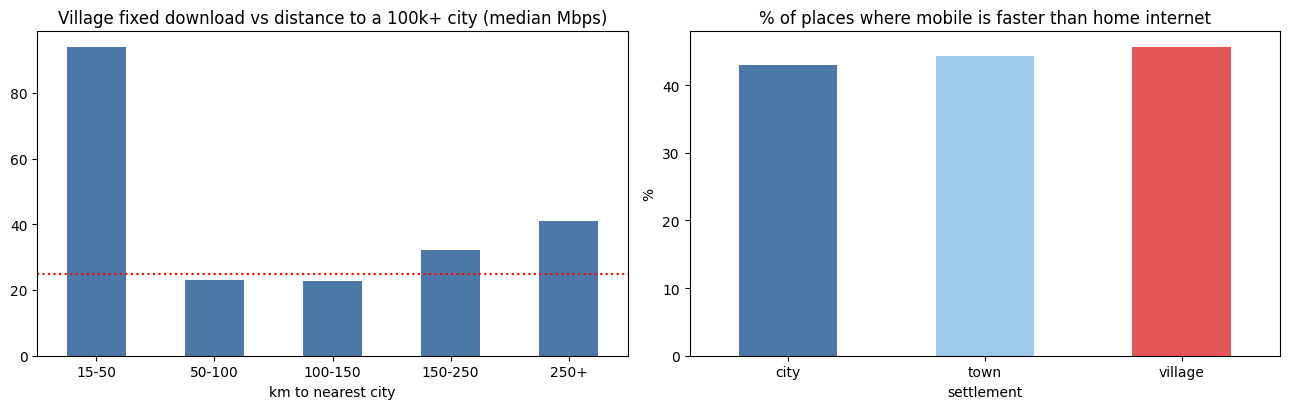

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
dist_tbl['median'].plot.bar(ax=ax[0], color='#4C78A8'); ax[0].set_title('Village fixed download vs distance to a 100k+ city (median Mbps)')
ax[0].set_xlabel('km to nearest city'); ax[0].tick_params(axis='x', rotation=0); ax[0].axhline(25, ls=':', c='red')
(wins.reindex(['city','town','village']) * 100).plot.bar(ax=ax[1], color=['#4C78A8', '#9ecae9', '#E45756'])
ax[1].set_title('% of places where mobile is faster than home internet'); ax[1].set_ylabel('%'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('charts_main.png', dpi=150); plt.show()

## 4. Charts

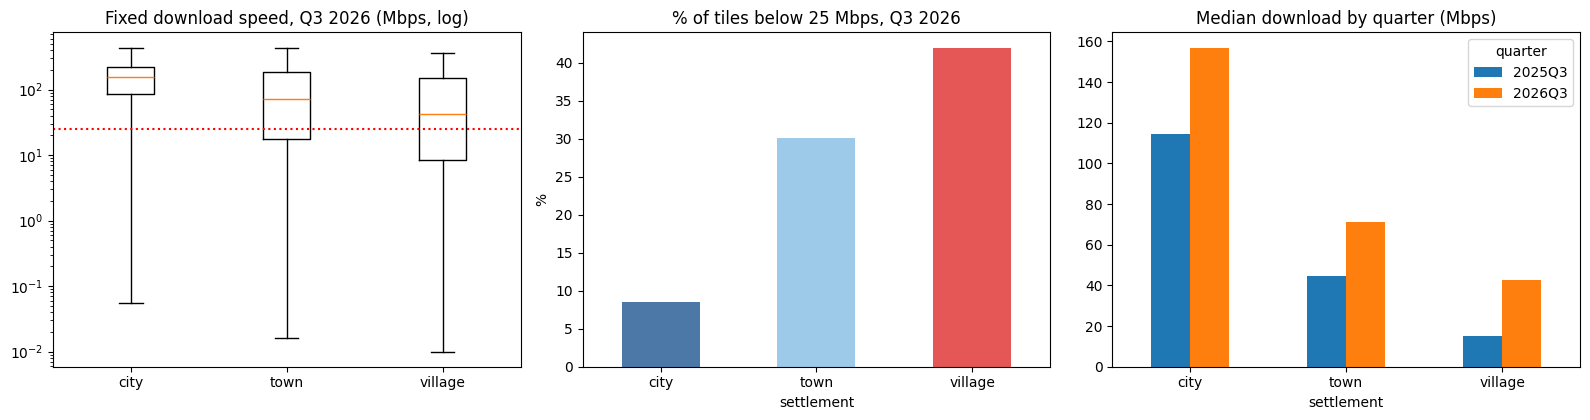

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
order = ['city', 'town', 'village']
data = [q[q.settlement == s].download_mbps for s in order]
ax[0].boxplot(data, tick_labels=order, showfliers=False); ax[0].set_yscale('log'); ax[0].axhline(25, ls=':', c='red')
ax[0].set_title('Fixed download speed, Q3 2026 (Mbps, log)')
(share.reindex(order) * 100).plot.bar(ax=ax[1], color=['#4C78A8', '#9ecae9', '#E45756']); ax[1].set_title('% of tiles below 25 Mbps, Q3 2026'); ax[1].set_ylabel('%')
med = fx.groupby(['settlement', 'quarter']).download_mbps.median().unstack().reindex(order)
med.plot.bar(ax=ax[2]); ax[2].set_title('Median download by quarter (Mbps)')
for a_ in ax: a_.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('charts.png', dpi=150); plt.show()

## 5. Summary

In [14]:
summary = pd.DataFrame([
 ('H0-1 download speed same in cities and villages (2026Q3)', 'Welch t on log + Mann-Whitney', f"median {cty.median():.0f} vs {vil.median():.0f} Mbps", p1),
 ('H0-2 share of tiles < 25 Mbps same in cities and villages', 'chi-square', f"{share['city']:.1%} vs {share['village']:.1%}", p2),
 ('H0-3 village speed same in 2025Q3 and 2026Q3', 'Welch t on log', f"median {v25.median():.0f} -> {v26.median():.0f} Mbps", p3),
 ('H0-4 village speed same near (<=50 km) and far (>150 km) from a city', 'Welch t on log + Mann-Whitney', f"median {near.median():.0f} vs {far.median():.0f} Mbps", p4),
 ('H0-5 share where mobile beats fixed same in cities and villages', 'chi-square', f"{wins['city']:.1%} vs {wins['village']:.1%}", p5),
], columns=['H0', 'test', 'numbers', 'p'])
summary['result'] = np.where(summary.p < 0.05, 'H0 rejected', 'H0 not rejected')
summary.to_csv('results.csv', index=False); summary

,H0,test,numbers,p,result
0,H0-1 download speed same in cities and village...,Welch t on log + Mann-Whitney,median 157 vs 43 Mbps,0.000000e+00,H0 rejected
1,H0-2 share of tiles < 25 Mbps same in cities a...,chi-square,8.5% vs 41.9%,0.000000e+00,H0 rejected
2,H0-3 village speed same in 2025Q3 and 2026Q3,Welch t on log,median 15 -> 43 Mbps,6.768413e-137,H0 rejected
3,H0-4 village speed same near (<=50 km) and far...,Welch t on log + Mann-Whitney,median 94 vs 35 Mbps,2.653007e-73,H0 rejected
4,H0-5 share where mobile beats fixed same in ci...,chi-square,42.9% vs 45.6%,5.863180e-03,H0 rejected
